# `vkvis`: Vulkan GPU Dimensionality Reduction & Neighbor Embedding (`mlx-vis` for Vulkan)

A pure-Vulkan GPU manifold learning & visualization library built on `vknumpy` + `vkshader` + `vkcolorcet` — **no CUDA, no Apple Silicon, no scikit-learn, no SciPy, no Matplotlib required!**

Includes **`UMAP`**, **`TSNE`**, **`PaCMAP`**, **`LocalMAP`**, **`TriMap`**, **`DREAMS`**, **`CNE`** (`infonce` / `nce` / `neg`), and **`NNDescent`**, plus 2D circle-splatting, **3D Vulkan sphere rendering**, side-by-side comparison grids, and live manifold unfolding animations.

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


UMAP          : 2558.5 ms


t-SNE         : 11521.3 ms


PaCMAP        : 3589.6 ms


LocalMAP      : 3823.9 ms


TriMap        : 3060.6 ms


DREAMS        : 11475.3 ms


CNE (InfoNCE) : 2470.5 ms


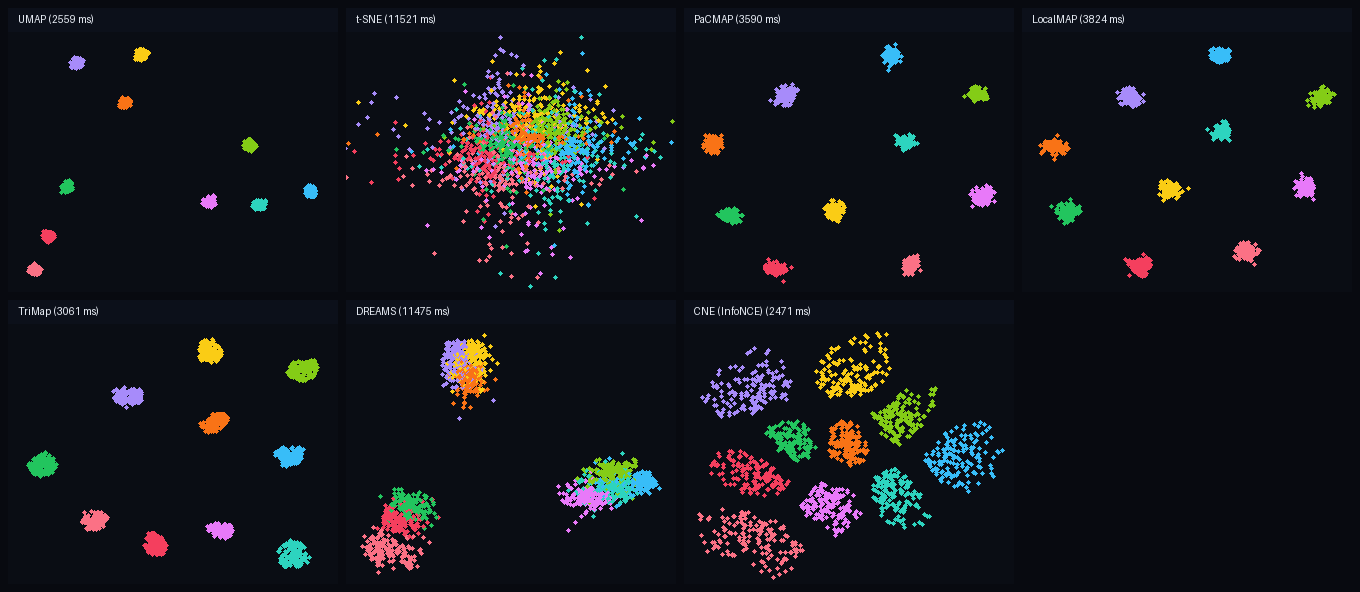

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vkvis as vv

# Build a 10-class 32-dimensional hierarchical cluster manifold (1,500 samples)
rng = np.random.default_rng(42)
n_clusters, per_c, dim = 10, 150, 32
super_centers = rng.standard_normal((3, dim)).astype(np.float32) * 5.0
centers = np.vstack([
    super_centers[c % 3] + rng.standard_normal((1, dim)).astype(np.float32) * 2.4
    for c in range(n_clusters)
])
X = np.vstack([centers[c] + rng.standard_normal((per_c, dim)).astype(np.float32) * 0.65 for c in range(n_clusters)])
y = np.repeat(np.arange(n_clusters, dtype=np.int32), per_c)

algos = {
    "UMAP": vv.UMAP(n_neighbors=15, n_epochs=140),
    "t-SNE": vv.TSNE(perplexity=30, n_iters=220),
    "PaCMAP": vv.PaCMAP(n_neighbors=10, n_iters=(70, 70, 110)),
    "LocalMAP": vv.LocalMAP(n_neighbors=10, n_iters=(70, 70, 110)),
    "TriMap": vv.TriMap(n_iters=180),
    "DREAMS": vv.DREAMS(perplexity=30, lam=0.15, n_iters=220),
    "CNE (InfoNCE)": vv.CNE(n_neighbors=15, loss="infonce", n_epochs=150),
}

embs = {}
umap_model = algos["UMAP"]
for name, model in algos.items():
    t0 = time.perf_counter()
    Y = model.fit_transform(X, record_every=10 if name == "UMAP" else 0)
    ms = (time.perf_counter() - t0) * 1000.0
    print(f"{name:14s}: {ms:6.1f} ms")
    embs[f"{name} ({ms:.0f} ms)"] = Y

vv.compare_embeddings(embs, labels=y, width=330, height=260, ncols=4, point_size=2)

## 2. Unrolling a 3D Swiss Roll Manifold & Interactive 3D UMAP (`n_components=3`)

Compare continuous-colored **2D UMAP / PaCMAP** unrolling a nonlinear 3D Swiss Roll alongside an interactive **3D UMAP** (`vkshader.interact_3d` Blinn–Phong shaded spheres)!

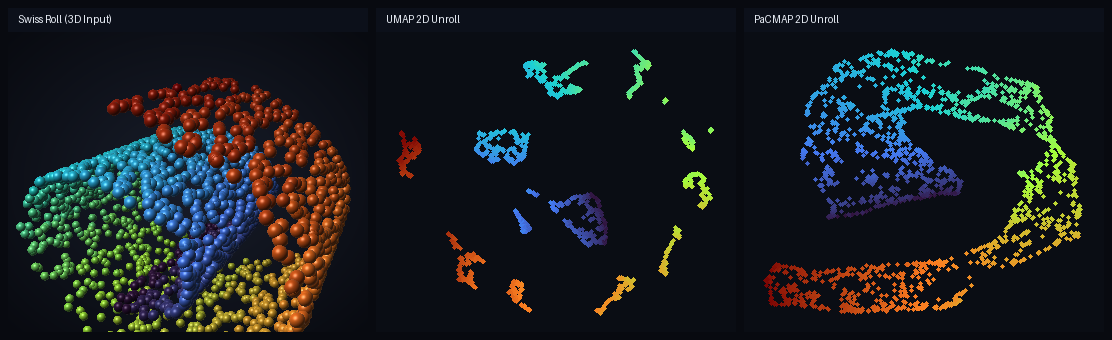

In [2]:
# Classic 3D Swiss Roll (2,000 points)
rng2 = np.random.default_rng(7)
t = 1.5 * np.pi * (1.0 + 2.0 * rng2.uniform(0.0, 1.0, 2000)).astype(np.float32)
h = rng2.uniform(0.0, 16.0, 2000).astype(np.float32)
X_swiss = np.column_stack([t * np.cos(t), h, t * np.sin(t)]).astype(np.float32)

Y_sw_umap = vv.UMAP(n_components=2, n_neighbors=15, n_epochs=150, seed=7).fit_transform(X_swiss)
Y_sw_pac  = vv.PaCMAP(n_components=2, n_neighbors=12, n_iters=(60, 60, 100), seed=7).fit_transform(X_swiss)
Y_3d_umap = vv.UMAP(n_components=3, n_neighbors=15, n_epochs=120, seed=42).fit_transform(X)

vv.compare_embeddings(
    {"Swiss Roll (3D Input)": X_swiss, "UMAP 2D Unroll": Y_sw_umap, "PaCMAP 2D Unroll": Y_sw_pac},
    labels=t, width=360, height=300, ncols=3, cmap="turbo", point_size=2,
)

## 3. Live UMAP Optimization Trajectory Player & 3D UMAP Sphere Orbit

Scrub or auto-play the GPU UMAP optimization trajectory (`umap_model.history_`), and orbit the **3D UMAP** embedding directly on your Vulkan GPU!

In [3]:
import io
import ipywidgets as widgets
from IPython.display import display
import vkpandas as vpd
import vkshader as vks

# 1. Pre-render UMAP optimization frames for instant playback
frames = vv.animate_embedding(umap_model.history_, labels=y, width=560, height=380, title_prefix="UMAP GPU Epoch")
jpg_frames = []
for im in frames:
    b = io.BytesIO()
    im.save(b, format="JPEG", quality=88)
    jpg_frames.append(b.getvalue())

img_w = widgets.Image(value=jpg_frames[-1], format="jpg", width=560, height=404)
play = widgets.Play(value=0, min=0, max=len(jpg_frames) - 1, step=1, interval=180, repeat=True, playing=True)
slider = widgets.IntSlider(value=0, min=0, max=len(jpg_frames) - 1, description="Frame:")
widgets.jslink((play, "value"), (slider, "value"))
play.observe(lambda ch: setattr(img_w, "value", jpg_frames[ch["new"]]), names="value")
display(widgets.VBox([widgets.HBox([play, slider]), img_w]))

# 2. Interactive 3D UMAP orbit viewer (drag to orbit, scroll to zoom)
df3 = vpd.DataFrame({"x": Y_3d_umap[:, 0], "y": Y_3d_umap[:, 1], "z": Y_3d_umap[:, 2], "cluster": y})
vks.interact_3d(df3, "x", "y", "z", kind="spheres", color_modes={"Cluster": ("cluster", None)}, basemap=None, width=680, height=460)

[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0
